# 03 — Exploratory Data Analysis & Annual Shifts

**Objective:** Conduct thorough exploratory data analysis including:
1. Target distribution analysis (CO and NOx skewness and kurtosis).
2. Correlation heatmap and collinearity diagnostics.
3. Annual operational shifts across 2011–2015.
4. Export publication-quality figures and summary tables.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def find_root():
    p = Path.cwd()
    for parent in [p] + list(p.parents):
        if (parent / 'data' / 'raw' / 'gt_2011.csv').exists():
            return parent
    return p

ROOT = find_root()
sys.path.insert(0, str(ROOT))

from src.data.loader import load_raw_yearly_data
from src.visualization.eda_plots import plot_correlation_heatmap, plot_annual_emission_trends


## 1. Loading Full Archive & Statistical Overview


In [2]:
df = load_raw_yearly_data(ROOT / "data" / "raw")
print(f"Dataset shape: {df.shape}")

# Statistical summary table
summary_table = df.describe().round(3).T
print(summary_table[["mean", "std", "min", "50%", "max"]])

out_annual_sum = ROOT / "outputs" / "tables" / "annual_summary.csv"
summary_table.to_csv(out_annual_sum)
print(f"Exported statistical summary to {out_annual_sum.relative_to(ROOT)}")


Dataset shape: (36733, 12)
                 mean     std       min       50%       max
AT             17.713   7.447    -6.235    17.801    37.103
AP           1013.070   6.463   985.850  1012.600  1036.600
AH             77.867  14.461    24.085    80.470   100.200
AFDP            3.926   0.774     2.087     3.938     7.611
GTEP           25.564   4.196    17.698    25.104    40.716
TIT          1081.428  17.536  1000.800  1085.900  1100.900
TAT           546.159   6.842   511.040   549.880   550.610
TEY           133.506  15.619   100.020   133.730   179.500
CDP            12.061   1.089     9.852    11.965    15.159
CO              2.372   2.263     0.000     1.714    44.103
NOX            65.293  11.678    25.905    63.849   119.910
source_year  2012.986   1.419  2011.000  2013.000  2015.000
Exported statistical summary to outputs\tables\annual_summary.csv


## 2. Target Emission Distributions
Analyzing carbon monoxide (CO) and nitrogen oxides (NOx) distributions. CO exhibits strong positive skewness with high peak concentrations during combustor transients, whereas NOx displays bimodal operational characteristics.


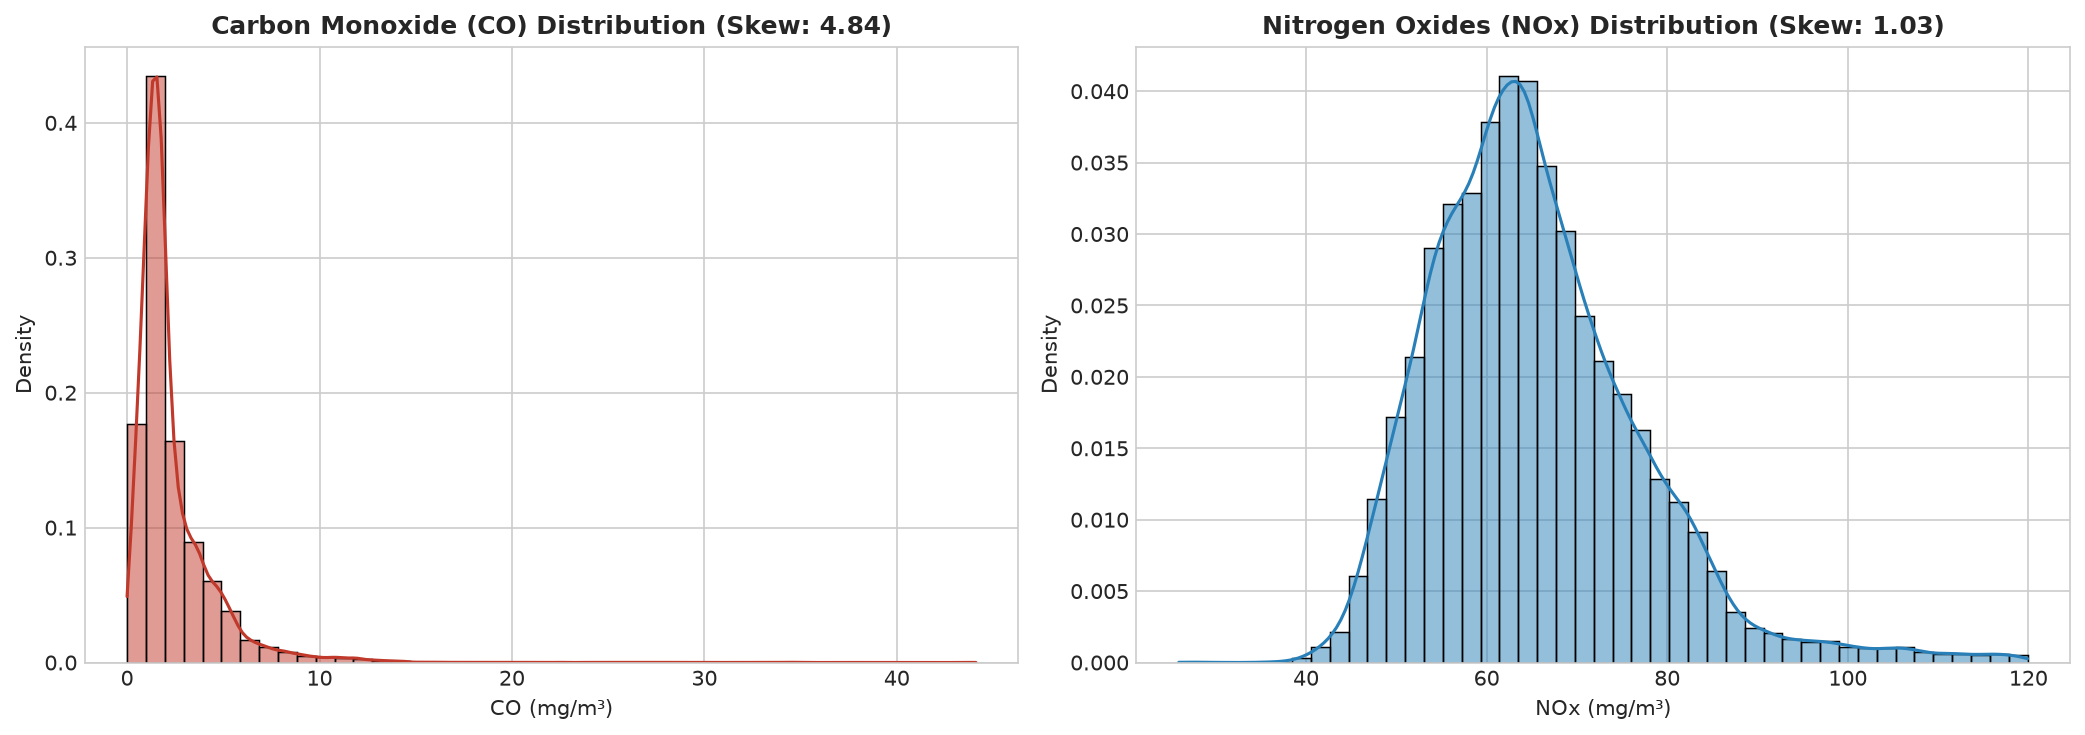

Saved target distribution figure to outputs\figures\target_distributions.png


In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# CO Distribution
sns.histplot(df["CO"], kde=True, ax=ax1, color="#c0392b", bins=45, stat="density")
ax1.set_title(f"Carbon Monoxide (CO) Distribution (Skew: {df['CO'].skew():.2f})", fontweight="bold")
ax1.set_xlabel("CO (mg/m³)")
ax1.set_ylabel("Density")

# NOx Distribution
sns.histplot(df["NOX"], kde=True, ax=ax2, color="#2980b9", bins=45, stat="density")
ax2.set_title(f"Nitrogen Oxides (NOx) Distribution (Skew: {df['NOX'].skew():.2f})", fontweight="bold")
ax2.set_xlabel("NOx (mg/m³)")
ax2.set_ylabel("Density")

plt.tight_layout()
out_tgt_fig = ROOT / "outputs" / "figures" / "target_distributions.png"
out_tgt_fig.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out_tgt_fig, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved target distribution figure to {out_tgt_fig.relative_to(ROOT)}")


## 3. Correlation Matrix & Multicollinearity Heatmap
Compressor Discharge Pressure (`CDP`), Gas Turbine Exhaust Pressure (`GTEP`), and Turbine Inlet Temperature (`TIT`) exhibit strong thermodynamic couplings with Turbine Energy Yield (`TEY`).


In [4]:
fig_corr = plot_correlation_heatmap(
    df,
    output_path=ROOT / "outputs" / "figures" / "correlation_heatmap.png",
    title="TURBINE-X: Inter-Sensor Correlation Matrix"
)
plt.show()
print("Saved correlation heatmap to outputs/figures/correlation_heatmap.png")


Saved correlation heatmap to outputs/figures/correlation_heatmap.png


## 4. Annual Emission Shifts (2011–2015)
Tracking emission dynamics across the 5 years.


In [5]:
annual_target_summary = df.groupby("source_year")[["CO", "NOX", "TEY"]].agg(["mean", "std", "median"]).round(3)
print(annual_target_summary)

out_ann_tgt = ROOT / "outputs" / "tables" / "annual_target_summary.csv"
annual_target_summary.to_csv(out_ann_tgt)
print(f"Exported annual target summary to {out_ann_tgt.relative_to(ROOT)}")

# Visual annual boxplots
fig_trends = plot_annual_emission_trends(
    df, 
    output_path=ROOT / "outputs" / "figures" / "annual_emission_trends.png"
)
plt.show()
print("Exploratory Data Analysis COMPLETE.")


                CO                   NOX                      TEY          \
              mean    std median    mean     std  median     mean     std   
source_year                                                                 
2011         1.572  1.845  1.156  67.575  10.683  65.542  135.746  16.209   
2012         2.361  2.474  1.636  68.789  10.225  67.246  132.676  15.302   
2013         2.723  2.364  1.783  70.008  12.048  68.651  132.168  16.348   
2014         2.081  2.007  1.655  60.067   9.972  59.278  132.908  13.603   
2015         3.130  2.235  2.533  59.891  11.132  56.838  133.993  16.179   

                     
             median  
source_year          
2011         133.81  
2012         133.76  
2013         133.57  
2014         133.42  
2015         131.60  
Exported annual target summary to outputs\tables\annual_target_summary.csv


D:\TURBINE_X_Full_Project\TURBINE_X_Full_Project\src\visualization\eda_plots.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="source_year", y="CO", data=df, ax=ax1, palette="Blues")
D:\TURBINE_X_Full_Project\TURBINE_X_Full_Project\src\visualization\eda_plots.py:81: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="source_year", y="NOX", data=df, ax=ax2, palette="Oranges")


Exploratory Data Analysis COMPLETE.
